In [1]:
### Project; Malaria cell image classification with deep learning models using transfer learning techniques

## Data acquisition

# Import libraries

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# extract dataset

zip_path = "/content/archive.zip"
extract_path = "malaria_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

dataset_path = os.path.join(extract_path, "cell_images")

# verify dataset structure

classes = os.listdir(dataset_path)

print(classes)

['Parasitized', 'Uninfected']


In [2]:
## Data preprocessing

import os
import random
import shutil

random.seed(42)

# Path to the original dataset
dataset_path = "malaria_dataset/cell_images"     # Change if needed

# New folder for the 200-image subset
subset_path = "malaria_subset_200"

classes = ["Parasitized", "Uninfected"]

# Remove existing subset folder
if os.path.exists(subset_path):
    shutil.rmtree(subset_path)

# Create class folders
for cls in classes:
    os.makedirs(os.path.join(subset_path, cls), exist_ok=True)

# Copy 100 images from each class
for cls in classes:
    source = os.path.join(dataset_path, cls)
    images = os.listdir(source)

    selected = random.sample(images, 100)

    for img in selected:
        shutil.copy(
            os.path.join(source, img),
            os.path.join(subset_path, cls, img)
        )

print("200-image subset created successfully.")

from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = 224
BATCH_SIZE = 16

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.20,
    rotation_range=20,
    zoom_range=0.15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    horizontal_flip=True
)

valid_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.20
)

train_generator = train_datagen.flow_from_directory(
    subset_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",
    shuffle=True,
    seed=42
)

val_generator = valid_datagen.flow_from_directory(
    subset_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    shuffle=False,
    seed=42
)

print("Training images :", train_generator.samples)
print("Validation images:", val_generator.samples)
print("Total images     :", train_generator.samples + val_generator.samples)

200-image subset created successfully.
Found 160 images belonging to 2 classes.
Found 40 images belonging to 2 classes.
Training images : 160
Validation images: 40
Total images     : 200


         Class  Images
0  Parasitized   13780
1   Uninfected   13780


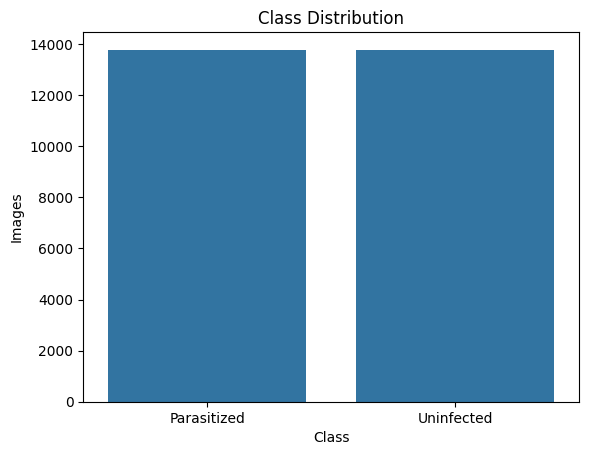

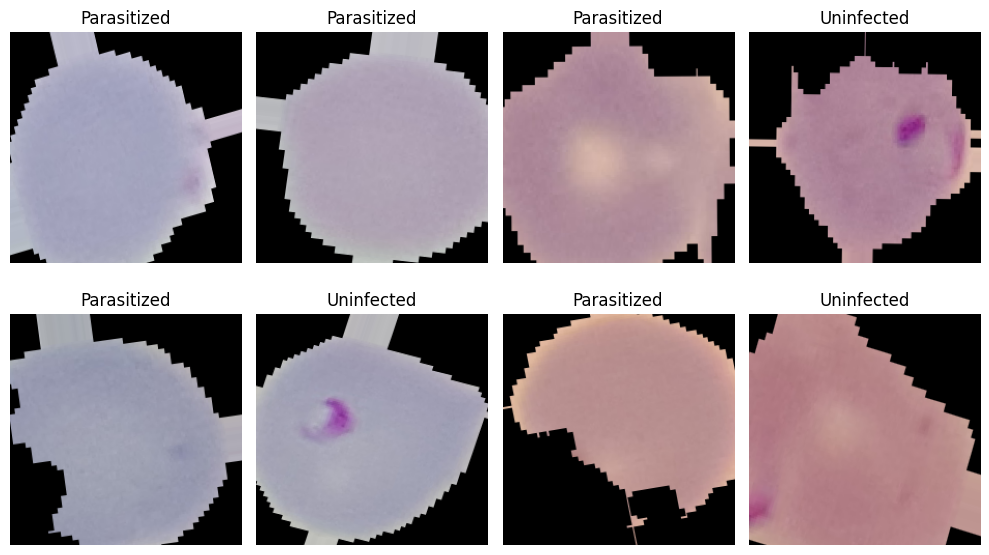

(115, 115)


In [3]:
## Exploratory data analysis

# count images per class

parasitized = len(os.listdir(os.path.join(dataset_path,"Parasitized")))
uninfected = len(os.listdir(os.path.join(dataset_path,"Uninfected")))

counts = pd.DataFrame({
    "Class":["Parasitized","Uninfected"],
    "Images":[parasitized,uninfected]
})

print(counts)

# visualize class distribution

sns.barplot(data=counts,x="Class",y="Images")
plt.title("Class Distribution")
plt.show()

# Display sample images

images, labels = next(train_generator)

plt.figure(figsize=(10,6))

for i in range(8):
    plt.subplot(2,4,i+1)
    plt.imshow(images[i])
    plt.title("Parasitized" if labels[i] else "Uninfected")
    plt.axis("off")

plt.tight_layout()
plt.show()

# Image dimension check

from PIL import Image

sample = os.path.join(
    dataset_path,
    "Parasitized",
    os.listdir(os.path.join(dataset_path,"Parasitized"))[0]
)

img = Image.open(sample)

print(img.size)

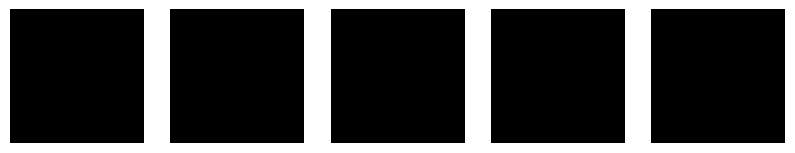

In [4]:
## Feature engineering

# Data augmentation check

augmentation = ImageDataGenerator(
    rotation_range=30,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8,1.2]
)

image = images[0]
image = np.expand_dims(image,0)

aug_iter = augmentation.flow(image,batch_size=1)

plt.figure(figsize=(10,3))

for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(next(aug_iter)[0])
    plt.axis("off")

plt.show()

# Transfer learning preprocessing

from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_pre
from tensorflow.keras.applications.resnet50 import preprocess_input as res_pre
from tensorflow.keras.applications.efficientnet import preprocess_input as eff_pre

In [5]:
## Model development

# Baseline model

from tensorflow.keras import Sequential
from tensorflow.keras.layers import *

cnn = Sequential([

    Conv2D(32,(3,3),activation='relu',input_shape=(224,224,3)),
    MaxPooling2D(),

    Conv2D(64,(3,3),activation='relu'),
    MaxPooling2D(),

    Conv2D(128,(3,3),activation='relu'),
    MaxPooling2D(),

    Flatten(),

    Dense(128,activation='relu'),
    Dropout(0.5),

    Dense(1,activation='sigmoid')

])

cnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_cnn = cnn.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 38s 4s/step - accuracy: 0.5000 - loss: 1.5846 - val_accuracy: 0.5000 - val_loss: 0.6888
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 25s 3s/step - accuracy: 0.5437 - loss: 0.6880 - val_accuracy: 0.5000 - val_loss: 0.6938
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.4812 - loss: 0.7002 - val_accuracy: 0.5000 - val_loss: 0.6919
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.6000 - loss: 0.6848 - val_accuracy: 0.5000 - val_loss: 0.6834
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.5188 - loss: 0.6828 - val_accuracy: 0.5000 - val_loss: 0.6994
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 0.5750 - loss: 0.6900 - val_accuracy: 0.5750 - val_loss: 0.6842
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 25s 3s/step - accuracy: 0.6375 - loss: 0.6507 - val_accuracy: 0.5000 - val_loss: 0.6844
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.7063 - loss: 0.5953 - val_accuracy: 0.5750 - val_loss:

In [35]:
# VGG16 Transfer learning

from tensorflow.keras.applications import VGG16

base_vgg = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

base_vgg.trainable=False

model_vgg = Sequential([

    base_vgg,

    GlobalAveragePooling2D(),

    Dense(128,activation='relu'),

    Dropout(0.5),

    Dense(1,activation='sigmoid')

])

model_vgg.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_vgg = model_vgg.fit(
    train_generator,
    validation_data=val_generator,
    epochs=8
)

# ResNet50

from tensorflow.keras.applications import ResNet50

base_res = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

base_res.trainable=False

model_res = Sequential([

    base_res,

    GlobalAveragePooling2D(),

    Dense(128,activation='relu'),

    Dropout(0.4),

    Dense(1,activation='sigmoid')

])

model_res.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_res = model_res.fit(
    train_generator,
    validation_data=val_generator,
    epochs=8
)

# EficientNetB0

from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

# Base model
base_eff = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

base_eff.trainable = False

# Functional model (recommended for Grad-CAM)
x = base_eff.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.3)(x)
output = Dense(1, activation="sigmoid")(x)

model_eff = Model(inputs=base_eff.input, outputs=output)

model_eff.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

Epoch 1/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 127s 12s/step - accuracy: 0.4688 - loss: 0.7563 - val_accuracy: 0.5500 - val_loss: 0.6813
Epoch 2/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 139s 14s/step - accuracy: 0.5938 - loss: 0.6922 - val_accuracy: 0.7750 - val_loss: 0.6642
Epoch 3/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 139s 14s/step - accuracy: 0.5375 - loss: 0.6740 - val_accuracy: 0.6250 - val_loss: 0.6528
Epoch 4/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 121s 12s/step - accuracy: 0.5875 - loss: 0.6708 - val_accuracy: 0.6250 - val_loss: 0.6452
Epoch 5/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 122s 12s/step - accuracy: 0.6313 - loss: 0.6389 - val_accuracy: 0.8000 - val_loss: 0.6339
Epoch 6/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 139s 14s/step - accuracy: 0.6875 - loss: 0.6247 - val_accuracy: 0.6000 - val_loss: 0.6364
Epoch 7/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 120s 12s/step - accuracy: 0.6938 - loss: 0.6149 - val_accuracy: 0.7750 - val_loss: 0.6140
Epoch 8/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 122s 12s/step - accuracy: 0.6687 - loss: 0.6233 - val_accuracy: 0.6250 - v

In [36]:
## Fine tuning

base_eff.trainable=True

for layer in base_eff.layers[:-20]:
    layer.trainable=False

model_eff.compile(

    optimizer=tf.keras.optimizers.Adam(1e-5),

    loss='binary_crossentropy',

    metrics=['accuracy']

)

history_ft = model_eff.fit(
    train_generator,
    validation_data=val_generator,
    epochs=5
)

Epoch 1/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.4563 - loss: 0.7196 - val_accuracy: 0.5000 - val_loss: 0.7126
Epoch 2/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.5562 - loss: 0.6946 - val_accuracy: 0.5000 - val_loss: 0.7144
Epoch 3/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.4812 - loss: 0.6914 - val_accuracy: 0.5000 - val_loss: 0.7152
Epoch 4/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.5188 - loss: 0.7001 - val_accuracy: 0.5000 - val_loss: 0.7157
Epoch 5/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.4688 - loss: 0.7110 - val_accuracy: 0.5000 - val_loss: 0.7172


In [23]:
import tensorflow as tf

# Build the model
dummy = tf.random.normal((1, 224, 224, 3))
_ = model_eff(dummy)

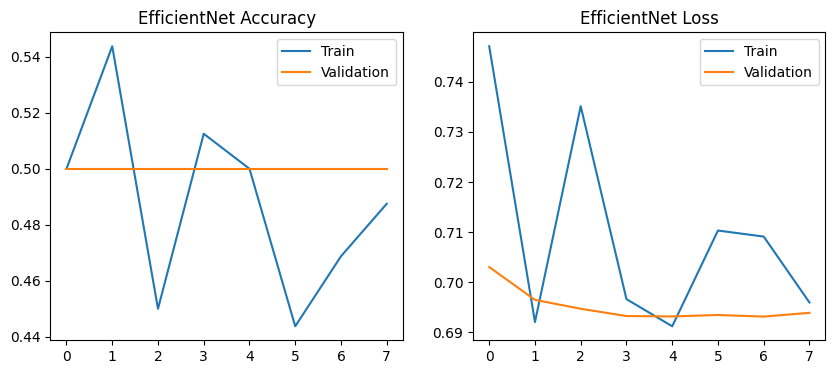

3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step
              precision    recall  f1-score   support

  Uninfected       0.50      1.00      0.67        20
 Parasitized       0.00      0.00      0.00        20

    accuracy                           0.50        40
   macro avg       0.25      0.50      0.33        40
weighted avg       0.25      0.50      0.33        40



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


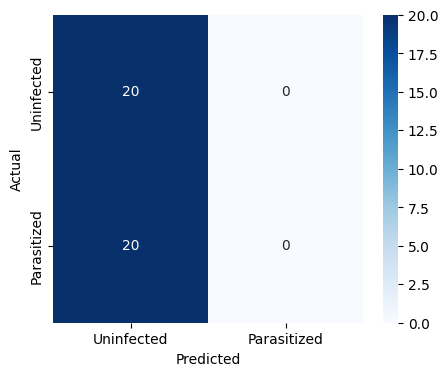

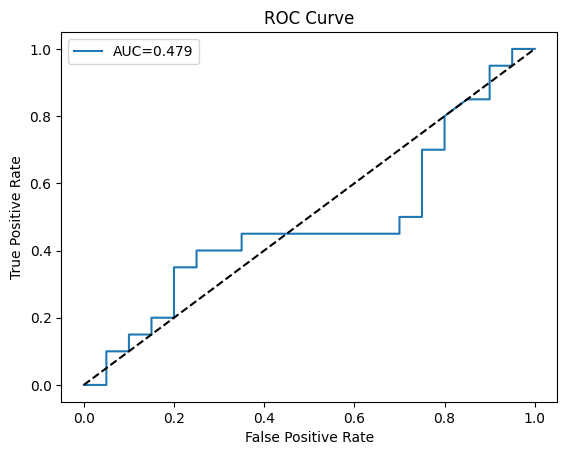

            Model  Validation Accuracy
0             CNN                  0.6
1           VGG16                  0.8
2        ResNet50                  0.6
3  EfficientNetB0                  0.5


In [37]:
## Model evaluation

# Accuracy and Loss curves

def plot_history(history,title):

    plt.figure(figsize=(10,4))

    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title(title+" Accuracy")
    plt.legend(['Train','Validation'])

    plt.subplot(1,2,2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title(title+" Loss")
    plt.legend(['Train','Validation'])

    plt.show()

plot_history(history_eff,"EfficientNet")

# Predictions

pred_prob = model_eff.predict(val_generator)

pred = (pred_prob>0.5).astype(int)

# Classification report

from sklearn.metrics import classification_report

print(classification_report(
    val_generator.classes,
    pred,
    target_names=['Uninfected','Parasitized']
))

# Confusion Matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    val_generator.classes,
    pred
)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    cmap="Blues",
    fmt="d",
    xticklabels=['Uninfected','Parasitized'],
    yticklabels=['Uninfected','Parasitized']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ROC curve

from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(
    val_generator.classes,
    pred_prob
)

roc_auc = auc(fpr,tpr)

plt.plot(fpr,tpr,label="AUC="+str(round(roc_auc,3)))
plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.title("ROC Curve")
plt.show()

# Model comparison

results = pd.DataFrame({

    "Model":[
        "CNN",
        "VGG16",
        "ResNet50",
        "EfficientNetB0"
    ],

    "Validation Accuracy":[

        max(history_cnn.history['val_accuracy']),
        max(history_vgg.history['val_accuracy']),
        max(history_res.history['val_accuracy']),
        max(history_eff.history['val_accuracy'])

    ]

})

print(results)

In [38]:
## Model explainability

import tensorflow as tf
import numpy as np

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):

    grad_model = tf.keras.models.Model(
        inputs=model.input,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        loss = predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))

    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)

    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.reduce_max(heatmap) + 1e-8

    return heatmap.numpy()

In [39]:
# Load image
img = tf.keras.preprocessing.image.load_img(
    img_path,
    target_size=(224,224)
)

img_array = tf.keras.preprocessing.image.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Generate Grad-CAM
heatmap = make_gradcam_heatmap(
    img_array,
    model_eff,
    last_conv_layer_name="top_conv"
)

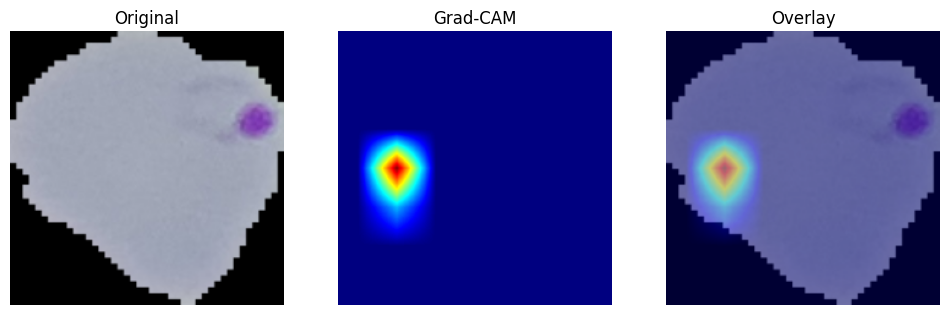

In [40]:
# Display the Grad-CAM

import cv2
import matplotlib.pyplot as plt

heatmap = cv2.resize(heatmap, (224,224))
heatmap = np.uint8(255 * heatmap)
heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

original = cv2.imread(img_path)
original = cv2.resize(original, (224,224))

overlay = cv2.addWeighted(original, 0.6, heatmap, 0.4, 0)

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB))
plt.title("Grad-CAM")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("Overlay")
plt.axis("off")

plt.show()

In [26]:
print(model_eff.built)
print(base_eff.built)

True
True
